# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [126]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split

import statsmodels.api as sm
from scipy.stats import norm
from statsmodels.base.model import GenericLikelihoodModel

NOTES FROM CLASS
- Living should be typically higher than deceased
- Deceased should be very skewed with low typical values for survival
- Replace you with the probability you survived 
    - If y 1 equals dead and 0 equals survive
    - For people we observe dying take logs of the number of months they live
    - For people who live, model with the probability that they live
- This is instead of imputing values for the people who live which will assume they follow the same distribution of those that died which is going to be a biased model

## Question 1

In [127]:
metabric = pd.read_csv('./data/metabric.csv')
metabric['Overall Survival Status'].value_counts()

Overall Survival Status
1:DECEASED    768
0:LIVING      575
Name: count, dtype: int64

<Axes: xlabel='Overall Survival (Months)', ylabel='Density'>

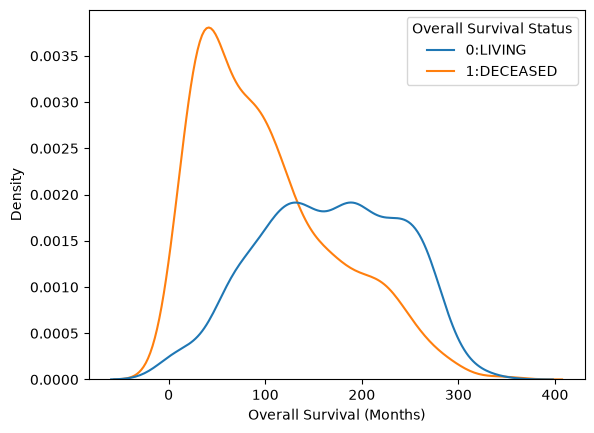

In [128]:
#dropping where Tumor Stage == 0
metabric_clean = metabric.query("`Tumor Stage` != 0.0")



#plotting KDE of Overall Survival (Months) hued by Overall Survival Status
sns.kdeplot(metabric, x='Overall Survival (Months)', hue= 'Overall Survival Status')

## Question 2

#### Imputation for living model:

In [129]:
import statsmodels.formula.api as smf

train, test = train_test_split(metabric_clean, test_size=0.2, random_state=42)

In [130]:
model_suvivalmonths = smf.ols(
    'Q("Overall Survival (Months)") ~ Q("Age at Diagnosis") + Q("Lymph nodes examined positive") + Q("Mutation Count") + C(Chemotherapy) + C(Q("Hormone Therapy")) + C(Q("Radio Therapy")) + C(Q("Tumor Stage"))',
    data=train,
).fit()
model_suvivalmonths.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                  OLS Regression Results                                  
==========================================================================================
Dep. Variable:     Q("Overall Survival (Months)")   R-squared:                       0.136
Model:                                        OLS   Adj. R-squared:                  0.129
Method:                             Least Squares   F-statistic:                     18.60
Date:                            Wed, 18 Nov 2026   Prob (F-statistic):           5.13e-29
Time:                                    15:13:59   Log-Likelihood:                -6120.4
No. Observations:                            1072   AIC:                         1.226e+04
Df Residuals:                                1062   BIC:                         1.231e+04
Df Model:                                       9                                         
Covariance Type:                        nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                            211.7045     13.371     15.833      0.000     185.467     237.942
C(Chemotherapy)[T.YES]               -31.8905      6.998     -4.557      0.000     -45.621     -18.160
C(Q("Hormone Therapy"))[T.YES]        -8.3323      5.109     -1.631      0.103     -18.356       1.692
C(Q("Radio Therapy"))[T.YES]           8.8846      4.965      1.790      0.074      -0.857      18.626
C(Q("Tumor Stage"))[T.2.0]           -15.3411      5.538     -2.770      0.006     -26.209      -4.474
C(Q("Tumor Stage"))[T.3.0]           -35.9766     10.164     -3.540      0.000     -55.921     -16.033
C(Q("Tumor Stage"))[T.4.0]           -40.5986     33.547     -1.210      0.226    -106.424      25.227
Q("Age at Diagnosis")                 -1.0348      0.202     -5.111      0.000      -1.432      -0.637
Q("Lymph nodes examined positive")    -3.0862      0.683     -4.516      0.000      -4.427      -1.745
Q("Mutation Count")                    0.7160      0.585      1.225      0.221      -0.431       1.863
==============================================================================
Omnibus:                       65.626   Durbin-Watson:                   2.033
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               30.211
Skew:                           0.204   Prob(JB):                     2.75e-07
Kurtosis:                       2.286   Cond. No.                         929.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [131]:
# 90% prediction intervals for individual log prices
prediction_survivalmonths = model_suvivalmonths.get_prediction(test).summary_frame(alpha=0.10)
comparison_survivalmonths = pd.DataFrame({
    'actual': test['Overall Survival (Months)'],
    'predicted': prediction_survivalmonths['mean'].to_numpy(),
    'lower': prediction_survivalmonths['obs_ci_lower'].to_numpy(),
    'upper': prediction_survivalmonths['obs_ci_upper'].to_numpy(),
})
coverage = comparison_survivalmonths['actual'].between(comparison_survivalmonths['lower'], comparison_survivalmonths['upper']).mean()
print(f'Test-set coverage of 90% prediction intervals: {coverage:.1%}')
comparison_survivalmonths.head()

Test-set coverage of 90% prediction intervals: 92.9%


,actual,predicted,lower,upper
804,260.200000,157.695899,36.596647,278.795152
550,250.133333,175.284813,54.231922,296.337705
572,252.333333,135.418266,14.243927,256.592604
432,236.933333,143.364834,22.206901,264.522767
260,43.866667,118.245356,-3.030042,239.520755


### Treating living as missing model:

In [132]:
metabric_clean_noliving = metabric_clean.query("`Overall Survival Status` != '0:LIVING'")

print(metabric_clean_noliving['Overall Survival Status'].value_counts())

train, test = train_test_split(metabric_clean_noliving, test_size=0.2, random_state=42)

Overall Survival Status
1:DECEASED    768
Name: count, dtype: int64


In [133]:
model_noliving = smf.ols(
    'Q("Overall Survival (Months)") ~ Q("Age at Diagnosis") + Q("Lymph nodes examined positive") + Q("Mutation Count") + C(Chemotherapy) + C(Q("Hormone Therapy")) + C(Q("Radio Therapy")) + C(Q("Tumor Stage"))',
    data=train,
).fit()
model_noliving.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                  OLS Regression Results                                  
==========================================================================================
Dep. Variable:     Q("Overall Survival (Months)")   R-squared:                       0.134
Model:                                        OLS   Adj. R-squared:                  0.121
Method:                             Least Squares   F-statistic:                     10.39
Date:                            Wed, 18 Nov 2026   Prob (F-statistic):           5.39e-15
Time:                                    15:13:59   Log-Likelihood:                -3444.0
No. Observations:                             614   AIC:                             6908.
Df Residuals:                                 604   BIC:                             6952.
Df Model:                                       9                                         
Covariance Type:                        nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Intercept                            146.9125     17.363      8.461      0.000     112.813     181.012
C(Chemotherapy)[T.YES]               -32.5124      8.833     -3.681      0.000     -49.859     -15.165
C(Q("Hormone Therapy"))[T.YES]         5.0157      6.402      0.784      0.434      -7.556      17.588
C(Q("Radio Therapy"))[T.YES]          -3.5991      5.888     -0.611      0.541     -15.162       7.964
C(Q("Tumor Stage"))[T.2.0]           -18.9430      6.823     -2.776      0.006     -32.344      -5.542
C(Q("Tumor Stage"))[T.3.0]           -33.6538     11.355     -2.964      0.003     -55.953     -11.354
C(Q("Tumor Stage"))[T.4.0]           -28.7869     34.372     -0.838      0.403     -96.290      38.716
Q("Age at Diagnosis")                 -0.3611      0.247     -1.463      0.144      -0.846       0.124
Q("Lymph nodes examined positive")    -2.3214      0.787     -2.951      0.003      -3.867      -0.776
Q("Mutation Count")                    0.9010      0.706      1.277      0.202      -0.485       2.287
==============================================================================
Omnibus:                       50.444   Durbin-Watson:                   2.101
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               61.335
Skew:                           0.771   Prob(JB):                     4.80e-14
Kurtosis:                       3.137   Cond. No.                         843.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [134]:
# 90% prediction intervals for individual log prices
prediction_noliving = model_noliving.get_prediction(test).summary_frame(alpha=0.10)
comparison_noliving = pd.DataFrame({
    'actual': test['Overall Survival (Months)'],
    'predicted': prediction_noliving['mean'].to_numpy(),
    'lower': prediction_noliving['obs_ci_lower'].to_numpy(),
    'upper': prediction_noliving['obs_ci_upper'].to_numpy(),
})
coverage = comparison_noliving['actual'].between(comparison_noliving['lower'], comparison_noliving['upper']).mean()
print(f'Test-set coverage of 90% prediction intervals: {coverage:.1%}')
comparison_noliving.head()

Test-set coverage of 90% prediction intervals: 93.5%


,actual,predicted,lower,upper
1172,146.933333,120.808172,10.445806,231.170537
690,28.066667,118.222354,7.723682,228.721027
1114,68.766667,110.241808,0.024061,220.459555
1210,9.700000,96.553716,-15.153190,208.260623
886,76.233333,89.505345,-21.426231,200.436921


#### Reflection:

**Explain clearly how the first option is an example of imputation and the second treats survival as missing data:**

The first model which runs an OLS model of `Overall survival (Months)` on all of the data ignores the fact that a subset of the data is still alive, and therefore does not have their true overall survival in months. This will skew the data towards the typical survival of those that are already deceased by assuming the currently living group will follow the same distribution as the deceased group. This makes it an example of imputation in the assumptions that are made for the living group based on the deceased. The second model drops all those in the data that are living and then runs the same OLS model of `Overall survival (Months)` but on this subset of the data. This treats survival as missing data, because it is only modeling how long people survive by those that are already deceased it will miss all of the variability in the data that comes from those that are living. This leads to even shorter survival prediction intervals.

### Question 3

To derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study and the survival probability based on the Normal distribution is used when the patient is alive when the study ends. The liklihood function will be the following:

$$
\prod_{i=1}^n \left[ \left\{ \frac{1}{\sqrt{2\pi}\,\sigma} \exp\left\{ -\frac{1}{2} \left( \frac{\log t_i - x_i\beta}{\sigma} \right)^2 \right\} \right\}^{d_i} \left\{ 1-\Phi\left( \frac{\log t_i - x_i\beta}{\sigma} \right) \right\}^{1-d_i} \right]
$$

$$
\ell(\beta,\sigma) = \sum_{i=1}^n \left[ d_i \left\{ -\log(\sqrt{2\pi}) - \log(\sigma) - \frac{(y_i - x_i\beta)^2}{2\sigma^2} \right\} + (1-d_i)\log(\left\{ 1-\Phi\!\left(\frac{\log t_i - x_i\beta}{\sigma}\right) \right\}) \right]
$$

### Question 4

In [147]:
from lifelines import LogNormalAFTFitter

cols = ["Overall Survival Status", "Overall Survival (Months)", "Age at Diagnosis", "Lymph nodes examined positive", "Mutation Count", "Chemotherapy", "Hormone Therapy", "Radio Therapy", "Tumor Stage"]
metabric_small = metabric_clean[cols].dropna()
metabric_small = metabric_small[metabric_small["Overall Survival (Months)"] > 0].copy() 


metabric_small["deceased"] = (metabric_small["Overall Survival Status"] == "1:DECEASED").astype(int)

train, test = train_test_split(metabric_small, test_size=0.2, random_state=42)

model_formula ='Q("Age at Diagnosis") + Q("Lymph nodes examined positive") + Q("Mutation Count") + C(Chemotherapy) + C(Q("Hormone Therapy")) + C(Q("Radio Therapy")) + C(Q("Tumor Stage"))'

aft = LogNormalAFTFitter()
aft.fit(train, duration_col="Overall Survival (Months)", event_col="deceased", formula=model_formula)
aft.print_summary()


<lifelines.LogNormalAFTFitter: fitted with 1072 total observations, 457 right-censored observations>
             duration col = 'Overall Survival (Months)'
                event col = 'deceased'
   number of observations = 1072
number of events observed = 615
           log-likelihood = -3857.29
         time fit was run = 2026-11-18 20:25:37 UTC

---
                                           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param  covariate                                                                                                                           
mu_    Intercept                           6.65    770.06      0.23            6.20            7.09              492.26             1204.63
       Q('Age at Diagnosis')              -0.02      0.98      0.00           -0.03           -0.02                0.97                0.98
       Q('Lymph nodes examined positive') -0.06      0.94      0.01           -0.08           -0.04                0.92                0.96
       Q('Mutation Count')                -0.02      0.98      0.01           -0.04            0.00                0.96                1.00
       C(Chemotherapy)[T.YES]             -0.30      0.74      0.12           -0.53           -0.07                0.59                0.93
       C(Q('Hormone Therapy'))[T.YES]      0.26      1.30      0.08            0.09            0.43                1.10                1.53
       C(Q('Radio Therapy'))[T.YES]        0.23      1.26      0.08            0.07            0.39                1.07                1.48
       C(Q('Tumor Stage'))[T.2.0]         -0.40      0.67      0.09           -0.58           -0.21                0.56                0.81
       C(Q('Tumor Stage'))[T.3.0]         -0.77      0.46      0.16           -1.09           -0.46                0.34                0.63
       C(Q('Tumor Stage'))[T.4.0]         -1.02      0.36      0.51           -2.02           -0.03                0.13                0.97
sigma_ Intercept                           0.09      1.09      0.03            0.03            0.15                1.03                1.16

                                           cmp to     z      p  -log2(p)
param  covariate                                                        
mu_    Intercept                             0.00 29.11 <0.005    616.59
       Q('Age at Diagnosis')                 0.00 -6.73 <0.005     35.76
       Q('Lymph nodes examined positive')    0.00 -5.51 <0.005     24.75
       Q('Mutation Count')                   0.00 -1.92   0.05      4.20
       C(Chemotherapy)[T.YES]                0.00 -2.60   0.01      6.73
       C(Q('Hormone Therapy'))[T.YES]        0.00  3.07 <0.005      8.86
       C(Q('Radio Therapy'))[T.YES]          0.00  2.85 <0.005      7.82
       C(Q('Tumor Stage'))[T.2.0]            0.00 -4.27 <0.005     15.64
       C(Q('Tumor Stage'))[T.3.0]            0.00 -4.78 <0.005     19.14
       C(Q('Tumor Stage'))[T.4.0]            0.00 -2.01   0.04      4.51
sigma_ Intercept                             0.00  2.89 <0.005      8.03
---
Concordance = 0.67
AIC = 7736.59
log-likelihood ratio test = 184.15 on 9 df
-log2(p) of ll-ratio test = 113.48

In [155]:
test["pred_logmonths_mle"] = np.log(test["pred_months_mle"])

sigma = np.exp(aft.params_.loc[("sigma_", "Intercept")])
mu = test["pred_logmonths_mle"]

comparison_mle = pd.DataFrame({
    "actual": test["Overall Survival (Months)"],
    "predicted": test["pred_months_mle"],
    "lower": np.exp(mu - 1.645 * sigma),
    "upper": np.exp(mu + 1.645 * sigma),
})
comparison_mle.head()

,actual,predicted,lower,upper
804,260.200000,214.461222,35.652688,1290.046220
550,250.133333,267.359234,44.446615,1608.243048
572,252.333333,183.924420,30.576157,1106.358529
432,236.933333,244.856719,40.705729,1472.883915
260,43.866667,226.260034,37.614159,1361.019483


### Question 5